<a href="https://colab.research.google.com/github/kamilabalabatyr/AI-Fundamentals/blob/main/24B031683_Lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Ячейка 1 — загрузка и статистика**

In [ ]:
!git clone -q https://github.com/Jakobovski/free-spoken-digit-dataset.git
import os, glob, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import librosa, librosa.display, IPython.display as ipd
warnings.filterwarnings('ignore')

DATA = 'free-spoken-digit-dataset/recordings'
files = sorted(glob.glob(f'{DATA}/*.wav'))

# Имя файла: {digit}_{speaker}_{index}.wav
meta = pd.DataFrame({'path': files})
meta['name'] = meta['path'].apply(os.path.basename) #'7_jackson_0.wav'
meta[['digit', 'speaker', 'rec']] = meta['name'].str.replace('.wav', '').str.split('_', expand=True)
meta['digit'] = meta['digit'].astype(int)
meta['rec'] = meta['rec'].astype(int)

print('Recordings:', len(meta))
print('Digits:', meta['digit'].nunique(), sorted(meta['digit'].unique()))
print('Speakers:', meta['speaker'].nunique(), sorted(meta['speaker'].unique()))
pd.crosstab(meta['speaker'], meta['digit'])

Recordings: 3000
Digits: 10 [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
Speakers: 6 ['george', 'jackson', 'lucas', 'nicolas', 'theo', 'yweweler']


digit,0,1,2,3,4,5,6,7,8,9
speaker,,,,,,,,,,
george,50,50,50,50,50,50,50,50,50,50
jackson,50,50,50,50,50,50,50,50,50,50
lucas,50,50,50,50,50,50,50,50,50,50
nicolas,50,50,50,50,50,50,50,50,50,50
theo,50,50,50,50,50,50,50,50,50,50
yweweler,50,50,50,50,50,50,50,50,50,50


**Ячейка 2 — прослушать запись**

In [ ]:
row = meta[meta['name'] == '7_jackson_0.wav'].iloc[0]
y, sr = librosa.load(row['path'], sr=None)   # sr=None: оставить родную частоту
print(f"Digit: {row['digit']} | Speaker: {row['speaker']} | Sampling rate: {sr} Hz | Duration: {len(y)/sr:.3f} s | Samples: {len(y)}")
ipd.Audio(y, rate=sr)

Digit: 7 | Speaker: jackson | Sampling rate: 8000 Hz | Duration: 0.432 s | Samples: 3457


**Ячейка 3 — waveform и spectrogram**

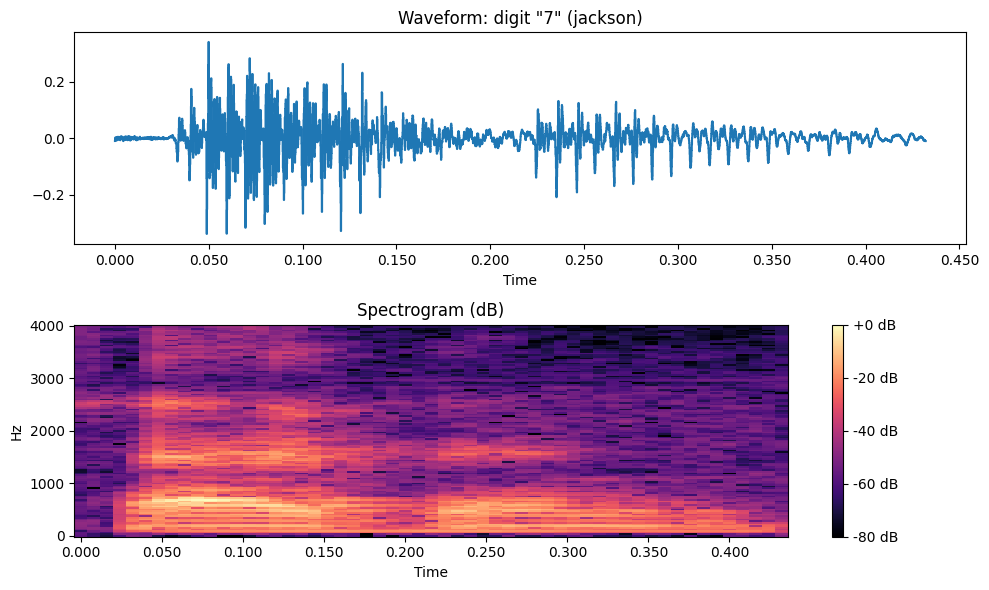

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6))
librosa.display.waveshow(y, sr=sr, ax=ax[0])
ax[0].set_title(f'Waveform: digit "{row["digit"]}" ({row["speaker"]})')

D = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=256, hop_length=64)), ref=np.max)
img = librosa.display.specshow(D, sr=sr, hop_length=64, x_axis='time', y_axis='hz', ax=ax[1])
ax[1].set_title('Spectrogram (dB)')
fig.colorbar(img, ax=ax[1], format='%+2.0f dB')
plt.tight_layout(); plt.show()

**Ячейка 4 — разделение по дикторам**

In [ ]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

y = meta['digit'].values          # метки: какая цифра
groups = meta['speaker'].values   # группы: какой диктор

# Внешнее разделение: 2 из 6 дикторов уходят в тест
gss = GroupShuffleSplit(n_splits=1, test_size=2/6, random_state=42)
train_idx, test_idx = next(gss.split(meta, y, groups))

train_speakers = sorted(set(groups[train_idx]))
test_speakers = sorted(set(groups[test_idx]))
print('Train speakers:', train_speakers, '| recordings:', len(train_idx))
print('Test speakers: ', test_speakers, '| recordings:', len(test_idx))

# Проверка: пересечения нет
assert set(train_speakers).isdisjoint(test_speakers)
print('No speaker overlap between train and test')

Train speakers: ['lucas', 'nicolas', 'theo', 'yweweler'] | recordings: 2000
Test speakers:  ['george', 'jackson'] | recordings: 1000
No speaker overlap between train and test


**Ячейка 5 — group-aware валидация на train**

In [ ]:
y_train, y_test = y[train_idx], y[test_idx]
groups_train = groups[train_idx]
cv = GroupKFold(n_splits=4)   # 4 тренировочных диктора  leave-one-speaker-out

for fold, (tr, va) in enumerate(cv.split(train_idx, y_train, groups_train)):
    print(f'Fold {fold}: train on {sorted(set(groups_train[tr]))} '
          f'-> validate on {sorted(set(groups_train[va]))}')

Fold 0: train on ['lucas', 'nicolas', 'theo'] -> validate on ['yweweler']
Fold 1: train on ['lucas', 'nicolas', 'yweweler'] -> validate on ['theo']
Fold 2: train on ['lucas', 'theo', 'yweweler'] -> validate on ['nicolas']
Fold 3: train on ['nicolas', 'theo', 'yweweler'] -> validate on ['lucas']


**Ячейка 6 — извлечение признаков**

In [ ]:
SR = 8000      # частота дискретизации FSDD
N_FFT = 512    # длина окна: 512 / 8000 = 64 мс
HOP = 128      # шаг окна: 16 мс

# Загружаем все записи один раз и храним в памяти
signals = [librosa.load(p, sr=None)[0] for p in meta['path']]

def extract_mean_mfcc(n_mfcc):
    """Для каждой записи: MFCC-матрица (n_mfcc x окна) -> среднее по времени -> вектор длины n_mfcc."""
    return np.array([
        librosa.feature.mfcc(y=s, sr=SR, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP).mean(axis=1)
        for s in signals
    ])

X20 = extract_mean_mfcc(20)
X20_train, X20_test = X20[train_idx], X20[test_idx]
print('X20:', X20.shape, '| train:', X20_train.shape, '| test:', X20_test.shape)

X20: (3000, 20) | train: (2000, 20) | test: (1000, 20)


**Ячейка 7 — baseline KNN**

In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

scoring = {'acc': 'accuracy', 'f1': 'f1_macro'}

baseline_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

# 1) Validation: GroupKFold по 4 тренировочным дикторам
cv_knn = cross_validate(baseline_knn, X20_train, y_train, groups=groups_train, cv=cv, scoring=scoring)
print('Accuracy по фолдам:', np.round(cv_knn['test_acc'], 3))
print(f"Validation: Accuracy = {cv_knn['test_acc'].mean():.3f}, Macro F1 = {cv_knn['test_f1'].mean():.3f}")

# 2) Финальная модель: обучаем на ВСЕЙ train-части, оцениваем на тесте один раз
baseline_knn.fit(X20_train, y_train)
pred = baseline_knn.predict(X20_test)
print(f'Test: Accuracy = {accuracy_score(y_test, pred):.3f}, '
      f'Macro F1 = {f1_score(y_test, pred, average="macro"):.3f}')

Accuracy по фолдам: [0.53  0.492 0.234 0.38 ]
Validation: Accuracy = 0.409, Macro F1 = 0.376
Test: Accuracy = 0.365, Macro F1 = 0.366


**Ячейка 8 — оценка обоих baseline + таблица результатов**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

all_results = []   # сюда будем складывать все системы для итоговой таблицы

def evaluate(system, model, X_tr, X_te, mfcc_desc, model_desc):
    """Validation по GroupKFold на train + одна финальная оценка на тестовых дикторах."""
    cvr = cross_validate(model, X_tr, y_train, groups=groups_train, cv=cv, scoring=scoring)
    model.fit(X_tr, y_train)
    pred = model.predict(X_te)
    all_results.append({
        'System': system, 'MFCC configuration': mfcc_desc, 'Model configuration': model_desc,
        'Val Accuracy': cvr['test_acc'].mean(), 'Val Macro F1': cvr['test_f1'].mean(),
        'Test Accuracy': accuracy_score(y_test, pred),
        'Test Macro F1': f1_score(y_test, pred, average='macro'),
    })
    return pred

baseline_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

pred_knn_base = evaluate('Baseline KNN', baseline_knn, X20_train, X20_test, '20 MFCC', 'KNN, k=5')
pred_rf_base  = evaluate('Baseline Random Forest', baseline_rf, X20_train, X20_test, '20 MFCC',
                         'RF, 100 trees, default params')

pd.DataFrame(all_results).round(3)

,System,MFCC configuration,Model configuration,Val Accuracy,Val Macro F1,Test Accuracy,Test Macro F1
0,Baseline KNN,20 MFCC,"KNN, k=5",0.409,0.376,0.365,0.366
1,Baseline Random Forest,20 MFCC,"RF, 100 trees, default params",0.491,0.463,0.387,0.383


**Ячейка 9 — отчёт по цифрам для baseline RF**

In [ ]:
print(classification_report(y_test, pred_rf_base, digits=2))

              precision    recall  f1-score   support

           0       0.15      0.30      0.20       100
           1       0.37      0.41      0.39       100
           2       0.45      0.25      0.32       100
           3       0.35      0.85      0.49       100
           4       0.55      0.51      0.53       100
           5       0.74      0.14      0.24       100
           6       0.44      0.21      0.28       100
           7       0.38      0.28      0.32       100
           8       0.96      0.44      0.60       100
           9       0.44      0.48      0.46       100

    accuracy                           0.39      1000
   macro avg       0.48      0.39      0.38      1000
weighted avg       0.48      0.39      0.38      1000



**Ячейка 10 — MFCC-визуализация**

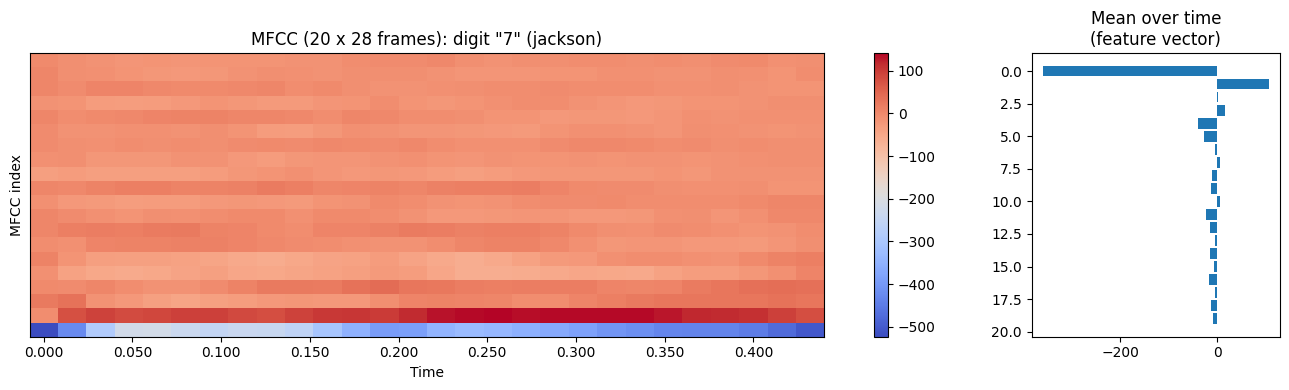

In [ ]:
signal_example, _ = librosa.load(row['path'], sr=None)
mfcc_example = librosa.feature.mfcc(y=signal_example, sr=SR, n_mfcc=20, n_fft=N_FFT, hop_length=HOP)
fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [4, 1]})
img = librosa.display.specshow(mfcc_example, sr=SR, hop_length=HOP, x_axis='time', ax=ax[0])
ax[0].set_ylabel('MFCC index'); ax[0].set_title(f'MFCC (20 x {mfcc_example.shape[1]} frames): digit "{row["digit"]}" ({row["speaker"]})')
fig.colorbar(img, ax=ax[0])
ax[1].barh(range(20), mfcc_example.mean(axis=1)); ax[1].invert_yaxis()
ax[1].set_title('Mean over time\n(feature vector)')
plt.tight_layout(); plt.show()

**Ячейка 11 — извлекаем 40 MFCC один раз**

In [ ]:
X40 = extract_mean_mfcc(40)
print('X40:', X40.shape)

# Проверка: первые n из 40 коэффициентов = извлечение с n_mfcc=n
assert np.allclose(X40[:, :20], X20)
print('X40[:, :20] == X20 -> можно брать срезы вместо повторного извлечения')

X40: (3000, 40)
X40[:, :20] == X20 -> можно брать срезы вместо повторного извлечения


**Ячейка 12 — автоматический поиск по n_mfcc**

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

candidates = list(range(5, 41))   # пространство поиска: n_mfcc = 5, 6, ..., 40
history = []

for n in candidates:
    Xn_train = X40[train_idx, :n]     # ТОЛЬКО тренировочные дикторы
    knn_f1 = cross_val_score(clone(baseline_knn), Xn_train, y_train, groups=groups_train, cv=cv, scoring='f1_macro').mean()
    rf_f1 = cross_val_score(clone(baseline_rf), Xn_train, y_train, groups=groups_train, cv=cv, scoring='f1_macro').mean()
    history.append({'n_mfcc': n, 'KNN val Macro F1': knn_f1, 'RF val Macro F1': rf_f1, 'Mean val Macro F1': (knn_f1 + rf_f1) / 2})

search_df = pd.DataFrame(history)
best_row = search_df.loc[search_df['Mean val Macro F1'].idxmax()]
BEST_N_MFCC = int(best_row['n_mfcc'])

print(f'Selected n_mfcc = {BEST_N_MFCC} | mean validation Macro F1 = {best_row["Mean val Macro F1"]:.3f}')
search_df.round(3)

Selected n_mfcc = 17 | mean validation Macro F1 = 0.436


,n_mfcc,KNN val Macro F1,RF val Macro F1,Mean val Macro F1
0,5,0.296,0.304,0.300
1,6,0.252,0.281,0.267
2,7,0.260,0.303,0.282
3,8,0.337,0.359,0.348
4,9,0.320,0.356,0.338
5,10,0.346,0.387,0.367
6,11,0.337,0.390,0.364
7,12,0.369,0.410,0.390
8,13,0.386,0.430,0.408
9,14,0.397,0.447,0.422


**Ячейка 13 — график поиска**

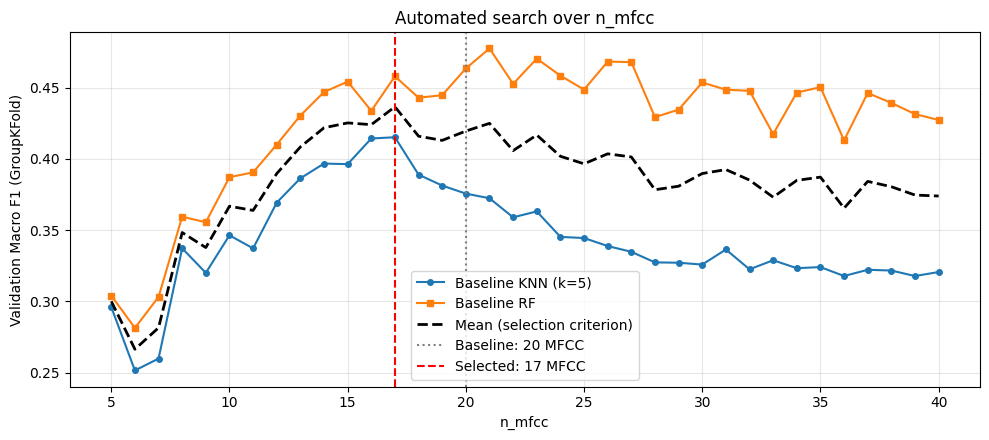

Best MFCC features: (2000, 17) (1000, 17)


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(search_df['n_mfcc'], search_df['KNN val Macro F1'], 'o-', ms=4, label='Baseline KNN (k=5)')
ax.plot(search_df['n_mfcc'], search_df['RF val Macro F1'], 's-', ms=4, label='Baseline RF')
ax.plot(search_df['n_mfcc'], search_df['Mean val Macro F1'], 'k--', lw=2, label='Mean (selection criterion)')
ax.axvline(20, color='gray', ls=':', label='Baseline: 20 MFCC')
ax.axvline(BEST_N_MFCC, color='red', ls='--', label=f'Selected: {BEST_N_MFCC} MFCC')
ax.set_xlabel('n_mfcc'); ax.set_ylabel('Validation Macro F1 (GroupKFold)')
ax.set_title('Automated search over n_mfcc'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# Признаки с выбранной конфигурацией — используем дальше в Частях 5–7
X_best_train = X40[train_idx, :BEST_N_MFCC]
X_best_test = X40[test_idx, :BEST_N_MFCC]
print('Best MFCC features:', X_best_train.shape, X_best_test.shape)

**Ячейка 14 — Grid Search для KNN**

In [ ]:
from sklearn.model_selection import GridSearchCV

knn_search = GridSearchCV(
    estimator=make_pipeline(StandardScaler(), KNeighborsClassifier()),
    param_grid={
        'kneighborsclassifier__n_neighbors': list(range(1, 102, 2)),   # 1, 3, ..., 101
        'kneighborsclassifier__weights': ['uniform', 'distance'],
        'kneighborsclassifier__metric': ['euclidean', 'manhattan'],
    },
    scoring='f1_macro',
    cv=cv,              # GroupKFold по 4 тренировочным дикторам
    n_jobs=-1,
)
knn_search.fit(X_best_train, y_train, groups=groups_train)

print('Best KNN parameters:', knn_search.best_params_)
print(f'Best validation Macro F1: {knn_search.best_score_:.3f}')

Best KNN parameters: {'kneighborsclassifier__metric': 'manhattan', 'kneighborsclassifier__n_neighbors': 63, 'kneighborsclassifier__weights': 'distance'}
Best validation Macro F1: 0.455


**Ячейка 15 — график валидации по k**

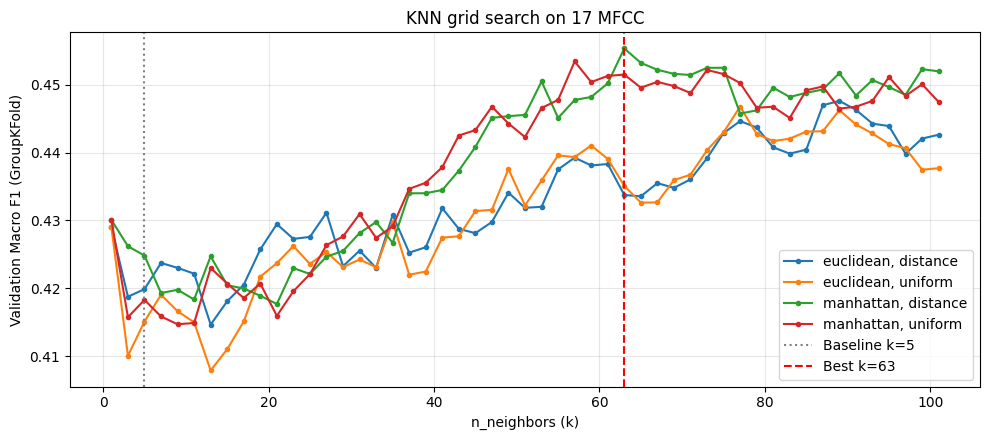

In [ ]:
knn_res = pd.DataFrame(knn_search.cv_results_)
fig, ax = plt.subplots(figsize=(10, 4.5))
for (metric, weights), grp in knn_res.groupby(['param_kneighborsclassifier__metric',
                                               'param_kneighborsclassifier__weights']):
    ax.plot(grp['param_kneighborsclassifier__n_neighbors'], grp['mean_test_score'],
            marker='o', ms=3, label=f'{metric}, {weights}')
best_k = knn_search.best_params_['kneighborsclassifier__n_neighbors']
ax.axvline(5, color='gray', ls=':', label='Baseline k=5')
ax.axvline(best_k, color='red', ls='--', label=f'Best k={best_k}')
ax.set_xlabel('n_neighbors (k)'); ax.set_ylabel('Validation Macro F1 (GroupKFold)')
ax.set_title(f'KNN grid search on {BEST_N_MFCC} MFCC'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Ячейка 16 — записываем KNN-системы в итоговые результаты**

In [ ]:
best_knn = knn_search.best_estimator_
bp = knn_search.best_params_
best_knn_desc = (f"KNN, k={bp['kneighborsclassifier__n_neighbors']}, "
                 f"{bp['kneighborsclassifier__metric']}, {bp['kneighborsclassifier__weights']}")

pred_knn_mfcc = evaluate('Optimized MFCC + baseline KNN', clone(baseline_knn),
                         X_best_train, X_best_test, f'{BEST_N_MFCC} MFCC', 'KNN, k=5')
pred_knn_best = evaluate('Best KNN', best_knn,
                         X_best_train, X_best_test, f'{BEST_N_MFCC} MFCC', best_knn_desc)

pd.DataFrame(all_results).round(3)

,System,MFCC configuration,Model configuration,Val Accuracy,Val Macro F1,Test Accuracy,Test Macro F1
0,Baseline KNN,20 MFCC,"KNN, k=5",0.409,0.376,0.365,0.366
1,Baseline Random Forest,20 MFCC,"RF, 100 trees, default params",0.491,0.463,0.387,0.383
2,Optimized MFCC + baseline KNN,17 MFCC,"KNN, k=5",0.448,0.415,0.376,0.389
3,Best KNN,17 MFCC,"KNN, k=63, manhattan, distance",0.480,0.455,0.396,0.398


**Ячейка 17 — Randomized Search для RF**

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 10, 15, 20, 30],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': [1, 2, 3, 4, 6, 8],
    'criterion': ['gini', 'entropy'],
}
# Всего комбинаций: 4*5*4*4*6*2 = 3840 → случайно проверяем 60

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=rf_param_dist,
    n_iter=60,
    scoring='f1_macro',
    cv=cv,                 # GroupKFold по тренировочным дикторам
    random_state=42,       # воспроизводимый выбор 60 комбинаций
    n_jobs=-1,
)
rf_search.fit(X_best_train, y_train, groups=groups_train)

print('Best RF parameters:', rf_search.best_params_)
print(f'Best validation Macro F1: {rf_search.best_score_:.3f}')

Best RF parameters: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 2, 'max_depth': 30, 'criterion': 'gini'}
Best validation Macro F1: 0.458


**Ячейка 18 — история поиска: топ-10 и влияние max_features**

,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,param_max_features,param_criterion,mean_test_score,std_test_score
36,300,30,2,2,2,gini,0.458,0.171
25,500,15,2,1,2,entropy,0.458,0.163
35,500,10,20,8,2,gini,0.456,0.188
53,500,15,5,1,2,gini,0.456,0.175
15,500,10,5,2,4,gini,0.456,0.182
59,200,15,5,1,2,entropy,0.455,0.153
31,500,20,20,4,2,gini,0.454,0.181
24,200,15,2,1,3,gini,0.454,0.162
33,200,15,2,8,2,gini,0.453,0.180
37,300,10,10,1,2,entropy,0.453,0.139


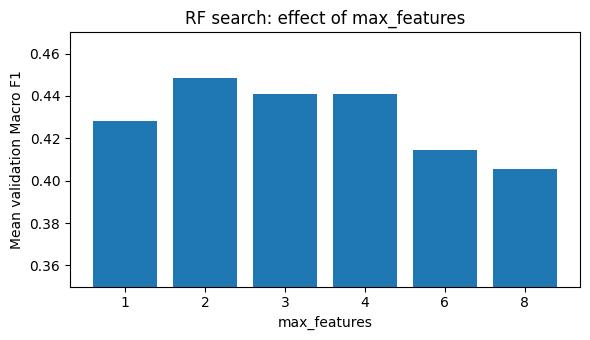

In [ ]:
rf_res = pd.DataFrame(rf_search.cv_results_).sort_values('rank_test_score')
show_cols = ['param_n_estimators', 'param_max_depth', 'param_min_samples_split',
             'param_min_samples_leaf', 'param_max_features', 'param_criterion',
             'mean_test_score', 'std_test_score']
display(rf_res[show_cols].head(10).round(3))

mf = rf_res.groupby('param_max_features')['mean_test_score'].mean()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(mf.index.astype(str), mf.values)
ax.set_xlabel('max_features'); ax.set_ylabel('Mean validation Macro F1')
ax.set_title('RF search: effect of max_features'); ax.set_ylim(0.35, 0.47)
plt.tight_layout(); plt.show()

**Ячейка 19 — записываем RF-системы в итоговые результаты**

In [ ]:
best_rf = rf_search.best_estimator_
best_rf_desc = ', '.join(f'{k}={v}' for k, v in rf_search.best_params_.items())

pred_rf_mfcc = evaluate('Optimized MFCC + baseline RF', clone(baseline_rf),
                        X_best_train, X_best_test, f'{BEST_N_MFCC} MFCC', 'RF, 100 trees, default params')
pred_rf_best = evaluate('Best Random Forest', best_rf,
                        X_best_train, X_best_test, f'{BEST_N_MFCC} MFCC', best_rf_desc)

pd.DataFrame(all_results).round(3)

,System,MFCC configuration,Model configuration,Val Accuracy,Val Macro F1,Test Accuracy,Test Macro F1
0,Baseline KNN,20 MFCC,"KNN, k=5",0.409,0.376,0.365,0.366
1,Baseline Random Forest,20 MFCC,"RF, 100 trees, default params",0.491,0.463,0.387,0.383
2,Optimized MFCC + baseline KNN,17 MFCC,"KNN, k=5",0.448,0.415,0.376,0.389
3,Best KNN,17 MFCC,"KNN, k=63, manhattan, distance",0.480,0.455,0.396,0.398
4,Optimized MFCC + baseline RF,17 MFCC,"RF, 100 trees, default params",0.486,0.458,0.384,0.380
5,Best Random Forest,17 MFCC,"n_estimators=300, min_samples_split=2, min_sam...",0.485,0.458,0.426,0.425


**Ячейка 20 — итоговая таблица**

In [ ]:
order = ['Baseline KNN', 'Optimized MFCC + baseline KNN', 'Best KNN',
         'Baseline Random Forest', 'Optimized MFCC + baseline RF', 'Best Random Forest']
final_df = pd.DataFrame(all_results).drop_duplicates('System', keep='last').set_index('System').loc[order].reset_index()
final_df.round(3)

,System,MFCC configuration,Model configuration,Val Accuracy,Val Macro F1,Test Accuracy,Test Macro F1
0,Baseline KNN,20 MFCC,"KNN, k=5",0.409,0.376,0.365,0.366
1,Optimized MFCC + baseline KNN,17 MFCC,"KNN, k=5",0.448,0.415,0.376,0.389
2,Best KNN,17 MFCC,"KNN, k=63, manhattan, distance",0.480,0.455,0.396,0.398
3,Baseline Random Forest,20 MFCC,"RF, 100 trees, default params",0.491,0.463,0.387,0.383
4,Optimized MFCC + baseline RF,17 MFCC,"RF, 100 trees, default params",0.486,0.458,0.384,0.380
5,Best Random Forest,17 MFCC,"n_estimators=300, min_samples_split=2, min_sam...",0.485,0.458,0.426,0.425


**Ячейка 21 — график сравнения**

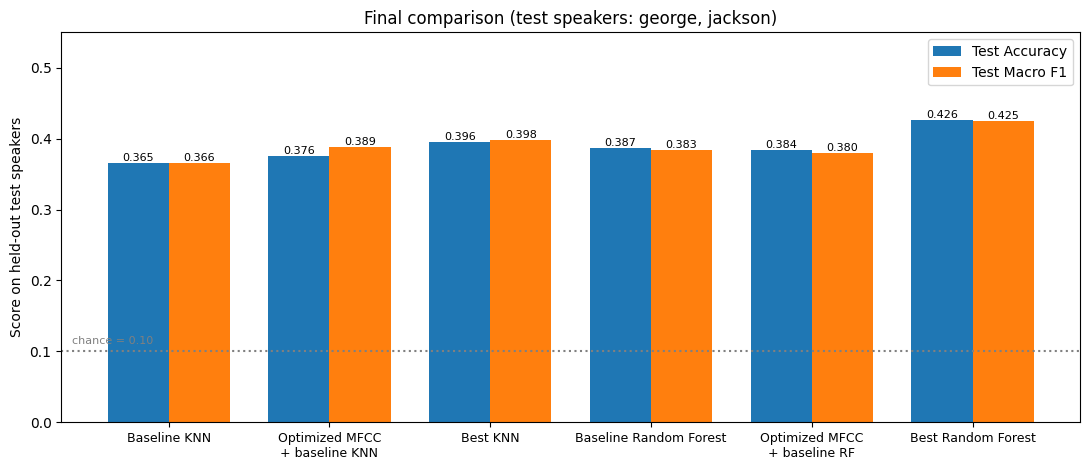

In [ ]:
fig, ax = plt.subplots(figsize=(11, 4.8))
xx = np.arange(len(final_df)); w = 0.38
b1 = ax.bar(xx - w/2, final_df['Test Accuracy'], w, label='Test Accuracy')
b2 = ax.bar(xx + w/2, final_df['Test Macro F1'], w, label='Test Macro F1')
ax.bar_label(b1, fmt='%.3f', fontsize=8); ax.bar_label(b2, fmt='%.3f', fontsize=8)
ax.set_xticks(xx)
ax.set_xticklabels([s.replace(' + ', '\n+ ') for s in final_df['System']], fontsize=9)
ax.axhline(0.1, color='gray', ls=':'); ax.text(-0.6, 0.11, 'chance = 0.10', fontsize=8, color='gray')
ax.set_ylabel('Score on held-out test speakers'); ax.set_ylim(0, 0.55)
ax.set_title(f'Final comparison (test speakers: {", ".join(test_speakers)})'); ax.legend()
plt.tight_layout(); plt.show()

**Ячейка 22 — confusion matrices**

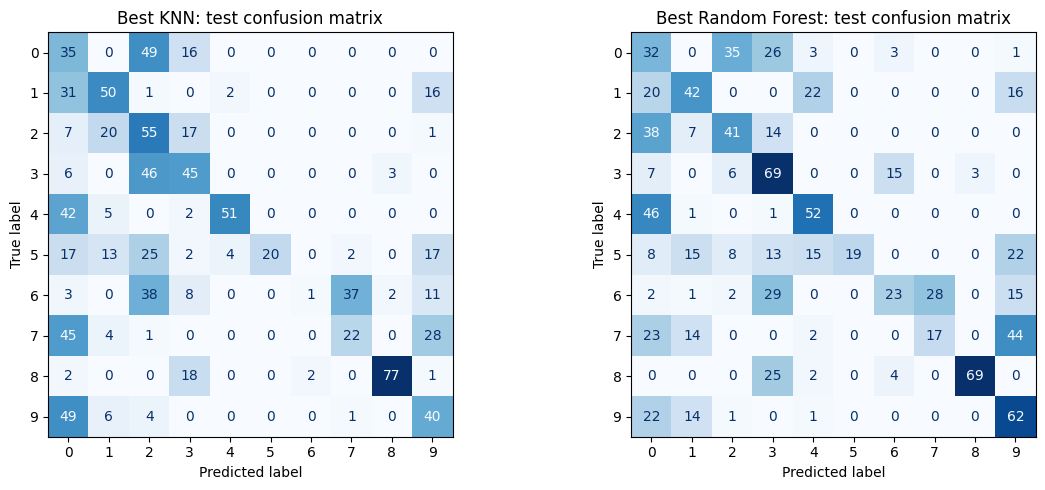

george: Best KNN acc = 0.218, Best RF acc = 0.330
jackson: Best KNN acc = 0.574, Best RF acc = 0.522


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, title in [(axs[0], pred_knn_best, 'Best KNN'), (axs[1], pred_rf_best, 'Best Random Forest')]:
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=range(10)).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{title}: test confusion matrix')
plt.tight_layout(); plt.show()

# Точность по каждому тестовому диктору
test_groups = groups[test_idx]
for spk in test_speakers:
    m = test_groups == spk
    print(f'{spk}: Best KNN acc = {accuracy_score(y_test[m], pred_knn_best[m]):.3f}, '
          f'Best RF acc = {accuracy_score(y_test[m], pred_rf_best[m]):.3f}')

**Ячейка 23 — Markdown-ячейка с выводом**

## Conclusion

**Optimization methods used.** MFCC: automated exhaustive stepwise search over n_mfcc = 5…40, selected by mean validation Macro F1 of baseline KNN and baseline RF (one MFCC configuration for both models). KNN: Grid Search (204 combinations of n_neighbors 1–101, weights, metric), because the space is small enough to evaluate fully; the range was widened beyond 51 because the first optimum lay at the edge. Random Forest: Randomized Search (60 of 3840 combinations), because the space is too large for a full grid. All searches used GroupKFold by speaker on the 4 training speakers only; the 2 test speakers (george, jackson) were used once, after selection.

**Best MFCC configuration:** 17 MFCC (mean over time) → 17 features.
**Best KNN:** k = 63, Manhattan distance, distance weighting (validation Macro F1 0.455 vs 0.376 for the baseline).
**Best Random Forest:** 300 trees, max_features = 2, max_depth = 30, min_samples_leaf = 2, min_samples_split = 2, gini (validation Macro F1 0.459, practically equal to the baseline 0.463/0.458).

**Best overall model:** Best Random Forest with test Accuracy 0.426 and Macro F1 0.425 (baseline RF: 0.387 / 0.383; best KNN: 0.396 / 0.398; chance level 0.10).

**Did the optimized MFCC help?** Yes for KNN: with the same k = 5, test Macro F1 rose from 0.366 to 0.389, because removing noisy high-order coefficients makes distances more meaningful. No for Random Forest (0.383 → 0.380, within noise), because trees ignore uninformative features on their own.

**Interpretation.** A random split gives ~96% accuracy, but speaker-independent evaluation gives ~40%: mean MFCC vectors mostly capture the speaker's voice, discard the temporal order of sounds, and only 4 training speakers are available. Accuracy also varies strongly between speakers (jackson ~52–57%, george ~22–33%), so differences of ~0.01 between configurations are within noise. The main bottleneck is the feature representation and the small number of training speakers rather than model hyperparameters.